# M09-3（選讀）| QDQ node fusion 涵蓋哪些 op

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/bobondemon/pt2e_quantize_and_deploy/blob/main/m09_onnx_runtime/03_qdq_fusion_coverage.ipynb)

M09-2 的 TinyConvNet 只有 conv、relu、maxpool、add、mean、linear，看不出每一級能做到什麼程度。這裡換成 `OpZooNet`（`common/models.py`，本專案的模型）：Conv、BN、Sigmoid、LeakyRelu、Concat、Mul、MaxPool、AveragePool、ReduceMean、MatMul、Gemm、Softmax 都有。

- **A.** fp32 ONNX：BASIC、EXTENDED 對沒有量化的圖做什麼。
- **B.** QDQ ONNX：EXTENDED 把每種 op 換成什麼，對照 ORT 原始碼的 fusion 清單。
- **C.** QDQ ONNX：LAYOUT、ALL 又改了什麼。

In [ ]:
#| include: false
# 在 Google Colab 上執行時：下載本教材的程式並安裝套件（第一次約需幾分鐘）。
# 在自己的電腦上執行時（環境見 README），這一格什麼都不做。
import sys

if "google.colab" in sys.modules:
    import os
    import subprocess

    repo = "/content/pt2e_quantize_and_deploy"
    if not os.path.exists(repo):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/bobondemon/pt2e_quantize_and_deploy.git", repo], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                        "--extra-index-url", "https://download.pytorch.org/whl/cpu",
                        "torch==2.14.0+cpu", "torchao==0.18.0", "onnx==1.23.0", "onnxscript==0.7.2",
                        "onnxruntime==1.30.0", "tabulate", "graphviz"], check=True)
    sys.path.insert(0, repo)  # 讓 notebook 能 import 本教材的 common/
    os.chdir(f"{repo}/m09_onnx_runtime")

In [1]:
import platform

import onnxruntime as ort
import torch

from common.pt2e import export_module, get_xnnpack_quantizer, quiet  # 必須在 onnx／torchao 之前 import
from common.env import env_summary
from common.graph_utils import short, unannotated_ops
from common.models import OpZooNet, example_inputs
from common.onnx_utils import LEVELS, onnx_op_counts, optimized_model, ort_quantize, to_onnx
from common.viz import draw_onnx, table

quiet()
_ = torch.manual_seed(0)
print(env_summary() + f"｜onnxruntime {ort.__version__}")
model = OpZooNet().eval()  # 只看圖，不用訓練
x = example_inputs()

Darwin arm64｜torch 2.14.0｜threads=4｜mkldnn=False｜nnpack=True｜onnxruntime 1.30.0


各等級改寫後的圖，用 M09-2 的 `optimized_model`（`SessionOptions.optimized_model_filepath` 存檔再讀回）取得：

In [2]:
def all_levels(onnx_model):
    """{"原圖": 匯出的圖, 等級: 改寫後的圖}。"""
    return {"原圖": onnx_model} | {lv: optimized_model(onnx_model, lv) for lv in LEVELS}


def counts_table(graphs):
    counts = {name: onnx_op_counts(g) for name, g in graphs.items()}
    ops = sorted(set().union(*counts.values()), key=lambda o: (-counts["原圖"].get(o, 0), o))
    return table([[op] + [counts[name].get(op, "") for name in graphs] for op in ops],
                 ["op"] + [n.replace("ORT_", "") for n in graphs])


def same_ops(a, b):
    return [n.op_type for n in a.graph.node] == [n.op_type for n in b.graph.node]

## A. fp32 ONNX：沒有量化的圖也會被改寫

`torch.onnx.export(OpZooNet, x, dynamo=True, optimize=False)`（`to_onnx(..., optimize=False)`）：關掉 `torch.onnx` 自己的圖最佳化，BN 與 Constant node 都留著，看 ORT 自己做多少。

In [3]:
fp32 = all_levels(to_onnx(model, x, optimize=False))
counts_table(fp32)

op,原圖,DISABLE_ALL,ENABLE_BASIC,ENABLE_EXTENDED,ENABLE_LAYOUT,ENABLE_ALL
Constant,3,,,,,
Conv,2,2,2,,,
AveragePool,1,1,1,1,1,1
BatchNormalization,1,1,,,,
Concat,1,1,1,1,1,1
Gemm,1,1,1,1,1,1
LeakyRelu,1,1,1,,,
MatMul,1,1,1,1,1,1
MaxPool,1,1,1,1,1,1
Mul,1,1,1,1,1,1


In [4]:
c = {lv: onnx_op_counts(g) for lv, g in fp32.items()}
assert "Constant" in c["原圖"] and "Constant" not in c["ORT_DISABLE_ALL"]
assert "BatchNormalization" in c["ORT_DISABLE_ALL"] and "BatchNormalization" not in c["ORT_ENABLE_BASIC"]
n_fused = c["ORT_ENABLE_EXTENDED"].get("com.microsoft.FusedConv", 0)
print(f"EXTENDED 的 com.microsoft.FusedConv：{n_fused} 個")
print(f"LAYOUT 與 EXTENDED 相同：{same_ops(fp32['ORT_ENABLE_LAYOUT'], fp32['ORT_ENABLE_EXTENDED'])}（{platform.machine()}）")

EXTENDED 的 com.microsoft.FusedConv：2 個
LAYOUT 與 EXTENDED 相同：True（arm64）


- **DISABLE_ALL**：Constant node 不見了。ORT 讀圖時就把它們當成常數（推論：轉成 initializer）。
- **BASIC**：`BatchNormalization` 折進前面的 Conv（`ConvBNFusion`）；只吃常數的 node 被常數摺疊算掉。
- **EXTENDED**：「Conv → Sigmoid」「Conv → LeakyRelu」融合成 `com.microsoft.FusedConv`（`ConvActivationFusion`）。這是 fp32 的融合，和量化無關。
- **LAYOUT**：fp32 Conv 的 NCHWc 只在 x86-64 啟用（ORT 原始碼），所以在 arm 上和 EXTENDED 相同。

BASIC、EXTENDED 不是只為量化存在。

## B. QDQ ONNX：EXTENDED 把每種 op 換成什麼

先用 M09-1 的 torchao 測試版 XNNPACKQuantizer 標一次，看哪些 op 沒有標籤：

In [5]:
gm = export_module(model, x)
get_xnnpack_quantizer(is_per_channel=True)[0].annotate(gm)
skipped = sorted({short(n.target) for n in unannotated_ops(gm) if n.op == "call_function"})
print("torchao 測試版 XNNPACKQuantizer 沒有標的 op：", skipped)

torchao 測試版 XNNPACKQuantizer 沒有標的 op： ['avg_pool2d', 'batch_norm', 'cat', 'leaky_relu', 'matmul', 'mean', 'sigmoid', 'softmax']


用它做 PT2E，這些 op 前後不會有 Q/DQ，看不出 ORT 對它們做什麼。所以這裡改用 ORT 自己的量化工具 `onnxruntime.quantization.quantize_static`（`ort_quantize`，細節在 M09-4），它在 fp32 ONNX 上替幾乎每個 op 插 Q/DQ：

In [6]:
fp32_onnx = to_onnx(model, x)
qdq = all_levels(ort_quantize(fp32_onnx, per_channel=True)[0])
counts_table(qdq)

op,原圖,DISABLE_ALL,ENABLE_BASIC,ENABLE_EXTENDED,ENABLE_LAYOUT,ENABLE_ALL
DequantizeLinear,21,22,22,2,2,2
QuantizeLinear,13,13,13,2,2,2
Conv,2,2,2,,,
AveragePool,1,1,1,,,
Concat,1,1,1,,,
Gemm,1,1,1,,,
LeakyRelu,1,1,1,,,
MatMul,1,1,1,,,
MaxPool,1,1,1,1,1,1
Mul,1,1,1,,,


ORT 1.30 原始碼（`qdq_selector_action_transformer.cc`，CPU EP 的部分）把 QDQ node fusion 分成幾組：

| 分組 | op | 結果 |
|---|---|---|
| 換成 int8 op | Conv | `QLinearConv` |
| | MatMul | `QLinearMatMul`；沒有輸出 Q 時是 `MatMulIntegerToFloat` |
| | Gemm | `com.microsoft.QGemm` |
| | Add、Mul、Concat | `com.microsoft.QLinearAdd`／`QLinearMul`／`QLinearConcat` |
| | AveragePool、GlobalAveragePool、Sigmoid | `com.microsoft.QLinear*` |
| | LeakyRelu、Softmax | `com.microsoft.QLinear*`（只有 CPU） |
| | Where | `com.microsoft.QLinearWhere` |
| 拿掉 Q/DQ | Reshape、Transpose、Flatten、Squeeze、Unsqueeze、Slice、Gather、GatherElements、Expand、Tile | op 不變，直接在 int8 上做 |
| | MaxPool、ReduceMax、ReduceMin | 同上；要求 scale 為正 |
| | Resize、DepthToSpace | 同上（只有 CPU） |
| | Split | 同上；要求輸入輸出的 qparams 相同 |
| 只拿掉 DQ | ArgMax | 輸出本來就是 index |
| 不在清單上 | 例如 ReduceMean | 留在 fp32，前後各一次 int8 ↔ fp32 |

「拿掉 Q/DQ」只限不改變數值、只搬資料或取大小的 op。MaxPool 要求 scale 為正，因為 scale 為負時大小順序會反過來。另有 `DQ → MatMul／Gemm` 換成 `MatMulNBits` 的規則，給 2／4／8-bit 的 weight-only 量化用。

對照 OpZooNet 在 EXTENDED 的實際結果：

In [7]:
GROUP = {op: "換成 int8 op" for op in ["Conv", "MatMul", "Gemm", "Add", "Mul", "Concat", "AveragePool",
                                     "GlobalAveragePool", "Sigmoid", "LeakyRelu", "Softmax", "Where"]}
GROUP |= {op: "拿掉 Q/DQ" for op in ["MaxPool", "ReduceMax", "ReduceMin", "Reshape", "Transpose", "Flatten", "Squeeze",
                                   "Unsqueeze", "Slice", "Gather", "Expand", "Tile", "Resize", "DepthToSpace", "Split"]}
ext = qdq["ORT_ENABLE_EXTENDED"]
ext_ops = onnx_op_counts(ext)
dq_out = {n.output[0] for n in ext.graph.node if n.op_type == "DequantizeLinear"}
rows, measured = [], {}
for op in dict.fromkeys(n.op_type for n in fp32_onnx.graph.node):  # 依出現順序、不重複
    if op in ext_ops:
        fp32_left = any(set(n.input) & dq_out for n in ext.graph.node if n.op_type == op)
        measured[op] = "不在清單上" if fp32_left else "拿掉 Q/DQ"
        result = "留在 fp32（前後仍有 DQ／Q）" if fp32_left else "原 op，直接在 int8 上做"
    else:
        repl = [o for o in ext_ops if o.split(".")[-1] in (f"QLinear{op}", f"Q{op}")]
        measured[op] = "換成 int8 op" if repl else "併進別的 op"
        result = f"換成 {', '.join(repl)}" if repl else "不見了（併進別的 op）"
    rows.append([op, GROUP.get(op, "不在清單上"), result])
table(rows, ["fp32 ONNX 的 op", "原始碼的分組", "實測（EXTENDED）"])

fp32 ONNX 的 op,原始碼的分組,實測（EXTENDED）
Conv,換成 int8 op,換成 QLinearConv
Sigmoid,換成 int8 op,換成 com.microsoft.QLinearSigmoid
LeakyRelu,換成 int8 op,換成 com.microsoft.QLinearLeakyRelu
Concat,換成 int8 op,換成 com.microsoft.QLinearConcat
Mul,換成 int8 op,換成 com.microsoft.QLinearMul
MaxPool,拿掉 Q/DQ,原 op，直接在 int8 上做
AveragePool,換成 int8 op,換成 com.microsoft.QLinearAveragePool
ReduceMean,不在清單上,留在 fp32（前後仍有 DQ／Q）
MatMul,換成 int8 op,換成 QLinearMatMul
Gemm,換成 int8 op,換成 com.microsoft.QGemm


In [8]:
mismatch = [op for op in measured if GROUP.get(op, "不在清單上") != measured[op]]
print("實測和原始碼分組不一致的 op：", mismatch)
assert not mismatch

實測和原始碼分組不一致的 op： []


每種 op 的結果都和原始碼的分組一致。留在 fp32 的是 `ReduceMean`：

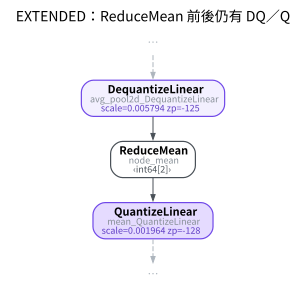

In [9]:
draw_onnx(ext, focus=lambda n: n.op_type == "ReduceMean", hops=1, title="EXTENDED：ReduceMean 前後仍有 DQ／Q")

留在 fp32 的 op 前後各一次 int8 ↔ fp32 轉換，和 M08-3 的 partition 邊界是同一種代價。模型能跑多少 int8，要對照這份清單，而不是只看 quantizer 標了什麼。

## C. QDQ ONNX：LAYOUT、ALL 又改了什麼

In [10]:
e, lay = onnx_op_counts(qdq["ORT_ENABLE_EXTENDED"]), onnx_op_counts(qdq["ORT_ENABLE_LAYOUT"])
changed = [[op, e.get(op, 0), lay.get(op, 0)] for op in sorted(set(e) | set(lay)) if e.get(op, 0) != lay.get(op, 0)]
table(changed, ["op", "EXTENDED", "LAYOUT"])

op,EXTENDED,LAYOUT
QLinearConv,2,0
Transpose,0,3
com.microsoft.QLinearConv,0,2


In [11]:
print("ALL 與 LAYOUT 相同：", same_ops(qdq["ORT_ENABLE_ALL"], qdq["ORT_ENABLE_LAYOUT"]))
assert {r[0] for r in changed} <= {"QLinearConv", "com.microsoft.QLinearConv", "Transpose"}
assert same_ops(qdq["ORT_ENABLE_ALL"], qdq["ORT_ENABLE_LAYOUT"])

ALL 與 LAYOUT 相同： True


- LAYOUT 的 `NhwcTransformer` 只把 `QLinearConv` 換成 NHWC 版本（`com.microsoft.QLinearConv`），前後插 `Transpose`。其他 int8 op（`QLinearSigmoid`、`QLinearConcat`…）不在它的清單上，維持 NCHW。
- ALL 只多 fp16 常數轉 fp32，和 LAYOUT 相同。

## 小結

- BASIC、EXTENDED 對 fp32 圖也有作用：BN 摺疊、Conv+激活融合。
- QDQ node fusion 有一份固定清單：一組換成 int8 op，一組只拿掉 Q/DQ；不在清單上的 op 留在 fp32。
- LAYOUT 只動 `QLinearConv`；ALL 和 LAYOUT 相同。